# Point tracking with CoTracker3: from pixels to camera motion

Multi-object tracking (notebook 01) follows *boxes*. Many robotics problems need something
finer: where does **this exact pixel** (a grasp point on a mug, a corner of a door, a feature
on the floor) go in every later frame, and is it still visible? That is **point tracking**
("tracking any point", TAP). Classic optical flow only links consecutive frames, so small
errors accumulate into drift and an occluded point is simply lost. Modern trackers such as
**CoTracker3** (Karaev et al. 2024) predict whole trajectories of many points *jointly*, with
an explicit **visibility** flag per frame, and keep tracking through occlusions.

In this notebook we:

1. load CoTracker3 from the pinned research code + Hugging Face weights,
2. track a dense grid and a mask-restricted grid on the official demo clip,
3. measure track quality *without* ground truth via forward-backward consistency,
4. use point tracks on the hand-held MOT17-05 clip to separate **camera ego-motion** from
   **independently moving people** (RANSAC homography), and score that against the GT boxes,
5. compare the **offline** and **online** (streaming) models in speed and GPU memory.

**What you'll learn:** the TAP problem formulation, how CoTracker's iterative transformer
updates tracks, what visibility/confidence mean, a GT-free quality check, and how point
tracks feed geometry (homographies, camera motion) for robotics.

**Prerequisites:** notebook 01 of this project (MOT17 data); homographies from project 01.
`make data-06_tracking` fetched the weights; `scripts/setup_third_party.sh` cloned the code.
Runtime: about 2 minutes on an RTX 5060 Laptop GPU.

## Setup

Standard setup plus the project helpers: `pointtrack.py` (CoTracker loading and inference,
forward-backward check, ego-motion fit) and `trackviz.py` (drawing). The CoTracker code is the
pinned clone in `third_party/co-tracker` (commit 82e02e8), put on `sys.path` by
`cvlab.io.add_third_party`.

In [1]:
# --- Setup: imports, device, paths and plotting style ---
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

import cvlab.device
import cvlab.io
import cvlab.viz

device = cvlab.device.setup(seed=0)
cvlab.viz.set_style()

PROJECT = "06_tracking"
ROOT = cvlab.io.repo_root()
sys.path.insert(0, str(cvlab.io.project_dir(PROJECT) / "scripts"))
import motlib as ml  # noqa: E402
import pointtrack as pt  # noqa: E402
import trackviz as tv  # noqa: E402

ASSETS_CT = cvlab.io.third_party_dir("co-tracker", "assets")
MOT05 = ml.load_sequence(cvlab.io.data_dir("mot17", "MOT17-05-FRCNN"))
print("CoTracker demo assets:", ASSETS_CT.relative_to(ROOT))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


CoTracker demo assets: third_party/co-tracker/assets


## 1. The point-tracking problem

Given a video $I_1, \dots, I_T$ and **query points** $q_n = (t_n, x_n, y_n)$, predict for every
frame $t$ the position $\mathbf{p}_{t,n} \in \mathbb{R}^2$ and a visibility
$v_{t,n} \in \{0, 1\}$. Queries can come from a grid, a mask, or a user click.

**How CoTracker3 does it** (simplified):

* A CNN extracts feature maps (stride 4) for every frame at the model resolution
  $384 \times 512$ (inputs are resized internally; outputs are scaled back).
* Every track starts at its query position. For each frame the model samples **4D correlation
  features**: local feature patches around the current estimate $\mathbf{p}_{t,n}$ correlated
  with the query's feature, at several scales.
* A transformer with attention **across time** (within a track) and **across tracks** (within a
  frame) refines all tracks jointly, a fixed number of times:
  $\mathbf{p}^{(k+1)} = \mathbf{p}^{(k)} + \Delta\mathbf{p}^{(k)}$, and predicts visibility and
  confidence logits. Attention across tracks is what lets a point behind an occluder "borrow"
  motion from its visible neighbours.
* **Offline** mode processes the whole clip at once (bidirectional in time). **Online** mode
  slides a 16-frame window with stride 8, only looking at past frames: the right choice for a
  robot that receives frames in real time.

CoTracker3 was trained on synthetic Kubric videos and then on real videos pseudo-labelled by
other trackers, which is why it works on real footage without fine-tuning.

apple.mp4: 50 frames of 1296x720 px


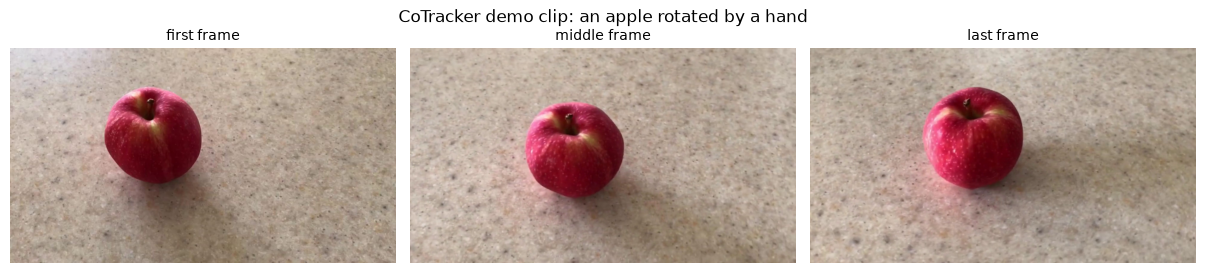

In [2]:
# --- Load the official demo clip (apple.mp4 from the CoTracker repository) ---
apple = cvlab.io.read_video_frames(ASSETS_CT / "apple.mp4")  # list of HxWx3 RGB uint8
print(f"apple.mp4: {len(apple)} frames of {apple[0].shape[1]}x{apple[0].shape[0]} px")
fig = cvlab.viz.show_images([apple[i] for i in (0, len(apple) // 2, len(apple) - 1)], ncols=3, size=4,
                            titles=["first frame", "middle frame", "last frame"],
                            suptitle="CoTracker demo clip: an apple rotated by a hand")
plt.show()

## 2. Loading CoTracker3

`pt.load_cotracker` builds the predictor class from the pinned code and loads
`scaled_offline.pth` (or `scaled_online.pth`) from the Hugging Face cache, which is what the
repository's `torch.hub` entry point does, minus cloning an unpinned branch at runtime.

In [3]:
# --- Build the offline CoTracker3 model and count its parameters ---
offline = pt.load_cotracker("offline", device=str(device))
n_params = sum(p.numel() for p in offline.parameters())
print(f"CoTracker3 offline: {n_params / 1e6:.1f} M parameters, model resolution {tuple(offline.interp_shape)}")
print(f"VRAM allocated after loading: {torch.cuda.memory_allocated() / 2**20:.0f} MiB")

CoTracker3 offline: 25.4 M parameters, model resolution (384, 512)
VRAM allocated after loading: 99 MiB


## 3. Tracking a grid of points

A `grid_size = 20` grid gives $20 \times 20 = 400$ query points on the first frame. The model
returns `tracks` $(T, N, 2)$ in pixels and `visible` $(T, N)$. Points are coloured by their
initial x position so you can follow them.

tracks (50, 400, 2), visible (50, 400); 50 frames in 2.40 s (20.9 FPS), peak VRAM 4987 MiB


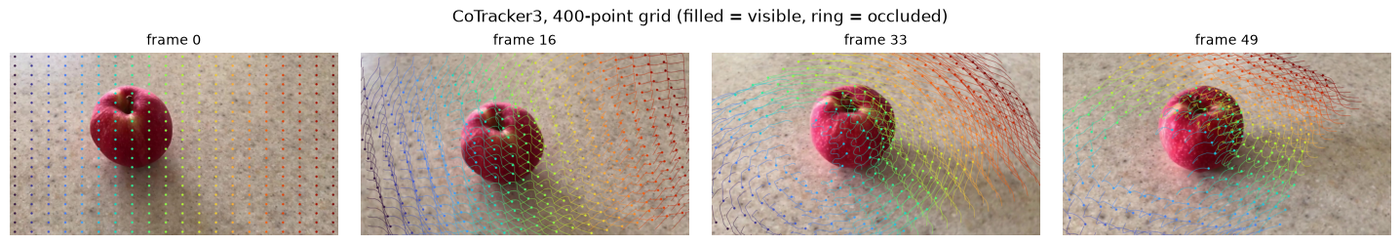

In [4]:
# --- Offline tracking of a 20x20 grid on the apple clip ---
res_apple = pt.track_offline(offline, apple, grid_size=20)
tracks, vis = res_apple["tracks"], res_apple["visible"]
colors = tv.point_colors(tracks[0])
print(f"tracks {tracks.shape}, visible {vis.shape}; {len(apple)} frames in {res_apple['seconds']:.2f} s "
      f"({len(apple) / res_apple['seconds']:.1f} FPS), peak VRAM {res_apple['peak_vram_mb']:.0f} MiB")
T = len(apple)
show_t = [0, T // 3, 2 * T // 3, T - 1]
imgs = [tv.draw_points(apple[t], tracks[t], vis[t], colors, radius=4,
                       history=tracks[max(0, t - 12):t + 1]) for t in show_t]
fig = cvlab.viz.show_images(imgs, ncols=4, size=3.6, titles=[f"frame {t}" for t in show_t],
                            suptitle="CoTracker3, 400-point grid (filled = visible, ring = occluded)")
cvlab.viz.savefig(fig, PROJECT, "cotracker_apple_grid")
plt.show()

### Visibility over time

Each row of the raster is one point, each column a frame. Points on the far side of the
rotating apple, or covered by the hand, become invisible and some reappear later: the tracker
keeps estimating their position while occluded (the rings above).

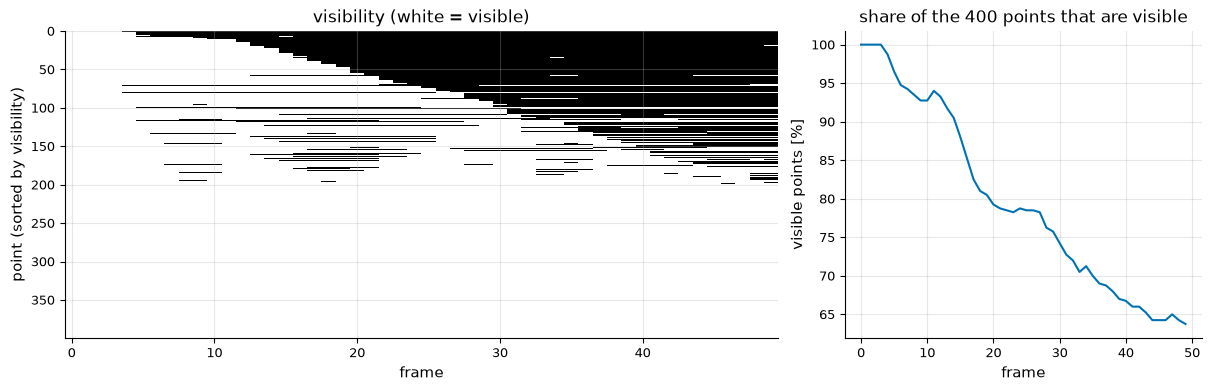

points visible in every frame: 50.0%; points occluded at least once and visible again later: 13.8%


In [5]:
# --- Visibility raster and the fraction of visible points per frame ---
order = np.argsort(vis.mean(axis=0))  # sort points by how often they are visible
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].imshow(vis[:, order].T, aspect="auto", cmap="gray", interpolation="nearest")
axes[0].set_xlabel("frame")
axes[0].set_ylabel("point (sorted by visibility)")
axes[0].set_title("visibility (white = visible)")
axes[1].plot(vis.mean(axis=1) * 100)
axes[1].set_xlabel("frame")
axes[1].set_ylabel("visible points [%]")
axes[1].set_title("share of the 400 points that are visible")
plt.show()
print(f"points visible in every frame: {vis.all(axis=0).mean():.1%}; "
      f"points occluded at least once and visible again later: "
      f"{((~vis).any(axis=0) & vis[-1]).mean():.1%}")

## 4. Tracking only the object: mask-conditioned grid

With `segm_mask` (a binary mask of the query frame) only grid points inside the mask are
tracked; this is how you would track points on an object a segmentation model (project 05)
has found. The CoTracker repository ships the apple's mask for frame 0.

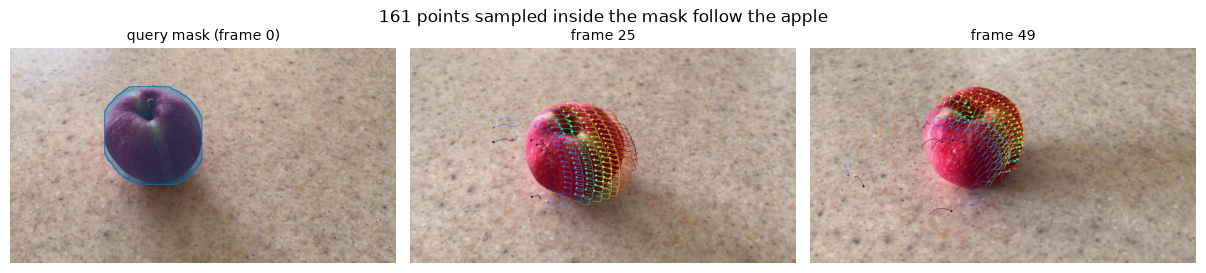

In [6]:
# --- Grid restricted to the apple mask (apple_mask.png, frame 0) ---
mask = cv2.imread(str(ASSETS_CT / "apple_mask.png"), cv2.IMREAD_GRAYSCALE) > 0
res_mask = pt.track_offline(offline, apple, grid_size=40, segm_mask=mask)
tm, vm = res_mask["tracks"], res_mask["visible"]
cm = tv.point_colors(tm[0])
imgs = [cvlab.viz.overlay_masks(apple[0], mask, alpha=0.35)]
imgs += [tv.draw_points(apple[t], tm[t], vm[t], cm, radius=3, history=tm[max(0, t - 8):t + 1])
         for t in (T // 2, T - 1)]
fig = cvlab.viz.show_images(imgs, ncols=3, size=4,
                            titles=["query mask (frame 0)", f"frame {T // 2}", f"frame {T - 1}"],
                            suptitle=f"{tm.shape[1]} points sampled inside the mask follow the apple")
plt.show()

## 5. A quality check without ground truth: forward-backward consistency

Point-tracking GT is expensive (TAP-Vid labels are hand-clicked). A cheap proxy: track a point
forward from frame 0 to the last frame, then track the **end point backwards** to frame 0 on
the time-reversed clip. A perfect tracker returns to the start, so the cycle error
$$e_n = \lVert \mathbf{p}^{\text{back}}_{0,n} - \mathbf{p}_{0,n} \rVert_2$$
flags unreliable tracks (only points visible in the last frame are evaluated). A small cycle
error is necessary, not sufficient: a tracker stuck on the wrong surface can be consistent.

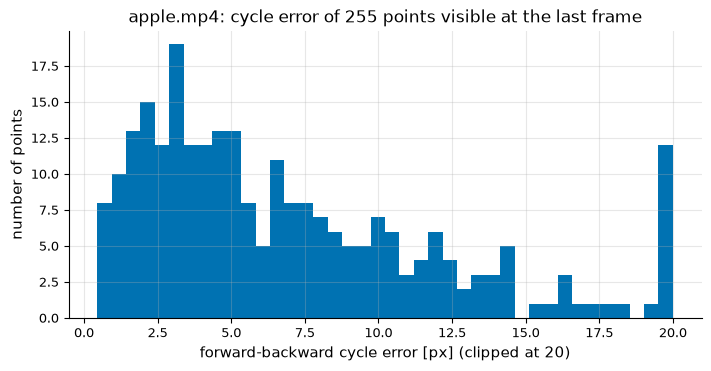

{'median [px]': 5.495, '< 2 px': 0.133, '< 5 px': 0.471}


In [7]:
# --- Forward-backward cycle error of the 400-point apple grid ---
fb_apple = pt.forward_backward_error(offline, apple, res_apple)
valid = np.isfinite(fb_apple)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(np.clip(fb_apple[valid], 0, 20), bins=40)
ax.set_xlabel("forward-backward cycle error [px] (clipped at 20)")
ax.set_ylabel("number of points")
ax.set_title(f"apple.mp4: cycle error of {valid.sum()} points visible at the last frame")
plt.show()
fb_stats = {"median [px]": np.median(fb_apple[valid]), "< 2 px": (fb_apple[valid] < 2).mean(),
            "< 5 px": (fb_apple[valid] < 5).mean()}
print({k: round(float(v), 3) for k, v in fb_stats.items()})

## 6. Robotics: separating camera motion from moving people

On a mobile robot the camera moves, so *everything* moves in the image. If the scene is far
away or roughly planar (or the camera mostly rotates), the image motion of the **static**
background between frame $0$ and frame $t$ is a homography:
$$\tilde{\mathbf{x}}_t \sim H_t\, \tilde{\mathbf{x}}_0 .$$
We fit $H_t$ with RANSAC on all visible tracks (people are outliers) and compute each point's
residual $r_{t,n} = \lVert \pi(H_t \tilde{\mathbf{x}}_{0,n}) - \mathbf{x}_{t,n} \rVert$. Points
whose median residual exceeds a few pixels move *independently* of the camera.
This is a classic first step of dynamic-object filtering in visual odometry / SLAM
(project 12), and the same idea as BoT-SORT's GMC, which fits a frame-to-frame affine warp.

We check it against MOT17's GT: are the "independently moving" points really on pedestrians?

In [8]:
# --- Track a 30x30 grid over the first CLIP_T frames of the hand-held MOT17-05 sequence ---
CLIP_T = 64  # ~4.6 s at 14 fps (offline mode needs ~6 GB for 64 frames, see section 7)
clip = [MOT05.frame(t) for t in range(1, CLIP_T + 1)]
res_mot = pt.track_offline(offline, clip, grid_size=30)
tr, vi = res_mot["tracks"], res_mot["visible"]
print(f"{tr.shape[1]} points x {CLIP_T} frames in {res_mot['seconds']:.2f} s, "
      f"peak VRAM {res_mot['peak_vram_mb']:.0f} MiB")

900 points x 64 frames in 5.27 s, peak VRAM 5826 MiB


Now the geometry. For every frame we fit $H_t$ to all point pairs (frame 0, frame $t$) with
RANSAC (3 px inlier threshold), compute each point's residual, and call a point *moving* when
its median residual over the frames where it is visible exceeds 6 px. We then check the
classification against the GT pedestrian boxes of the first frame: precision (how many
"moving" points lie on a person), recall (how many person points are flagged) and the base
rate (the precision a random guess would get).

,value
points evaluated,505.000
flagged moving,232.000
precision (moving -> on a person),0.267
recall (person points flagged),0.925
base rate (points on persons),0.133


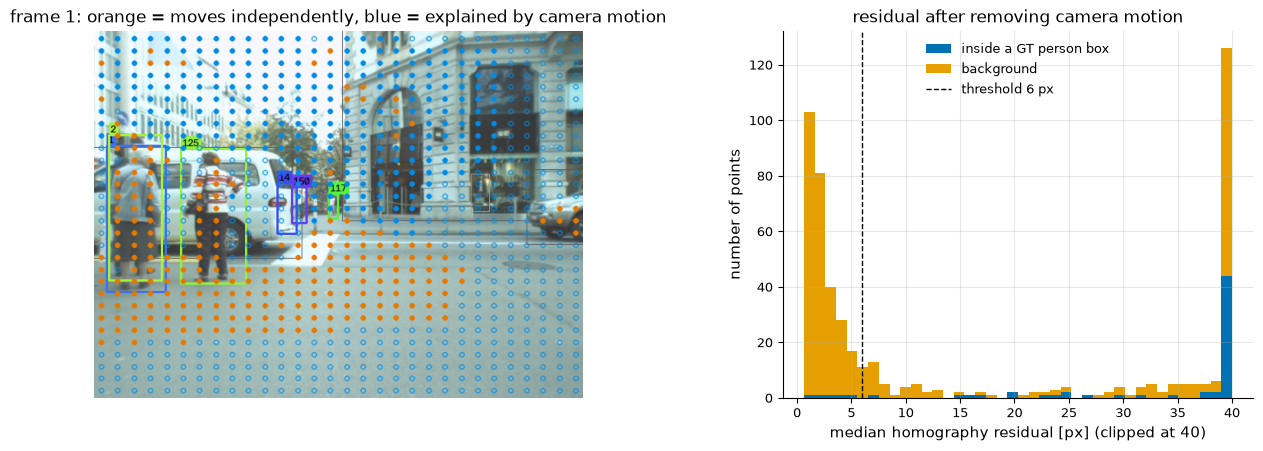

In [9]:
# --- Fit H_t with RANSAC, flag points with a large residual, and score against GT boxes ---
resid, Hs = pt.ego_motion_residuals(tr, vi, ref=0, ransac_px=3.0)
med = np.nanmedian(resid[1:], axis=0)  # median over frames where the point is visible
seen = np.isfinite(med) & (np.isfinite(resid[1:]).sum(axis=0) >= 10)
MOVING_PX = 6.0
moving = seen & (med > MOVING_PX)
gt = MOT05.gt()
gt1 = gt[(gt[:, 0] == 1) & (gt[:, 7] == ml.PEDESTRIAN) & (gt[:, 6] != 0)]
on_person = pt.points_in_boxes(tr[0], gt1[:, 2:6])  # query points inside a GT pedestrian box
ego = {
    "points evaluated": int(seen.sum()),
    "flagged moving": int(moving.sum()),
    "precision (moving -> on a person)": float(on_person[moving].mean()),
    "recall (person points flagged)": float(moving[on_person & seen].mean()),
    "base rate (points on persons)": float(on_person[seen].mean()),
}
display(pd.Series(ego).to_frame("value").round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [4 / 3 * 1.2, 1]})
img = tv.draw_gt(clip[0], gt[gt[:, 0] == 1])
pc = np.where(moving[:, None], [[230, 120, 0]], [[0, 140, 230]]).astype(np.uint8)
axes[0].imshow(tv.draw_points(img, tr[0], seen, pc, radius=3))
axes[0].set_title("frame 1: orange = moves independently, blue = explained by camera motion")
axes[0].axis("off")
axes[1].hist([np.clip(med[seen & on_person], 0, 40), np.clip(med[seen & ~on_person], 0, 40)],
             bins=40, stacked=True, label=["inside a GT person box", "background"])
axes[1].axvline(MOVING_PX, color="k", ls="--", lw=1, label=f"threshold {MOVING_PX:.0f} px")
axes[1].set_xlabel("median homography residual [px] (clipped at 40)")
axes[1].set_ylabel("number of points")
axes[1].set_title("residual after removing camera motion")
axes[1].legend()
cvlab.viz.savefig(fig, PROJECT, "ego_motion_segmentation")
plt.show()

The camera's own motion is also recovered: the translation part of $H_t$ (how far the image
centre moves) gives the apparent pan of the hand-held camera over time.

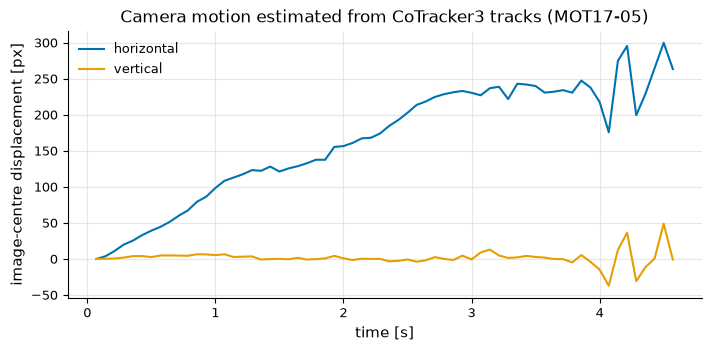

In [10]:
# --- Apparent camera pan: where the image centre of frame 1 lands in frame t ---
c0 = np.array([[[MOT05.width / 2, MOT05.height / 2]]], dtype=np.float32)
pan = np.array([cv2.perspectiveTransform(c0, H)[0, 0] - c0[0, 0] if H is not None else [np.nan, np.nan]
                for H in Hs])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, CLIP_T + 1) / MOT05.frame_rate, pan[:, 0], label="horizontal")
ax.plot(np.arange(1, CLIP_T + 1) / MOT05.frame_rate, pan[:, 1], label="vertical")
ax.set_xlabel("time [s]")
ax.set_ylabel("image-centre displacement [px]")
ax.set_title("Camera motion estimated from CoTracker3 tracks (MOT17-05)")
ax.legend()
plt.show()

## 7. Offline vs online: speed and GPU memory

The offline model attends over the whole clip, so memory grows with the number of frames $T$
and points $N$. The online model only ever holds one 16-frame window (plus a short memory).
We measure wall-clock time and peak allocated VRAM (`torch.cuda.max_memory_allocated`) for
increasing clip lengths at $N = 400$ points, and for increasing $N$ at a fixed $T$.

In [11]:
# --- Sweep clip length and number of points for the offline and online models ---
# Clip lengths and grid sizes of the sweep (a grid of g x g query points):
SWEEP_T = [16, 32, 48, 64, 96, 128]
SWEEP_T_MAX = 128
GRID_T = 48
SWEEP_GRID = [10, 20, 30, 40]
online = pt.load_cotracker("online", device=str(device))
frames_all = [MOT05.frame(t) for t in range(1, SWEEP_T_MAX + 1)]
runs = []
for mode, model, fn in [("offline", offline, pt.track_offline), ("online", online, pt.track_online)]:
    for T_ in SWEEP_T:
        for g in ([20] if T_ != GRID_T else SWEEP_GRID):
            try:
                r = fn(model, frames_all[:T_], grid_size=g)
                runs.append({"mode": mode, "frames": T_, "points": g * g, "seconds": r["seconds"],
                             "FPS": T_ / r["seconds"], "peak VRAM [MiB]": r["peak_vram_mb"]})
            except torch.OutOfMemoryError:
                torch.cuda.empty_cache()
                runs.append({"mode": mode, "frames": T_, "points": g * g, "seconds": np.nan,
                             "FPS": np.nan, "peak VRAM [MiB]": np.nan, "note": "out of memory"})
sweep = pd.DataFrame(runs)
print(f"{len(sweep)} runs done")

18 runs done


Do the two modes agree? On the same clip we compare their positions for points that both call
visible. The online model never sees the future, so differences concentrate where points are
occluded and later reappear.

In [12]:
# --- Agreement between online and offline tracks on the CLIP_T-frame MOT17-05 clip ---
res_on = pt.track_online(online, clip, grid_size=30)
both = res_on["visible"] & vi
dist = np.linalg.norm(res_on["tracks"] - tr, axis=-1)[both]
agree = {"median distance [px]": float(np.median(dist)), "< 2 px": float((dist < 2).mean()),
         "visibility agreement": float((res_on["visible"] == vi).mean())}
print({k: round(v, 3) for k, v in agree.items()})

{'median distance [px]': 0.881, '< 2 px': 0.745, 'visibility agreement': 0.962}


Finally an animation of the moving-camera clip for the README: points explained by the camera
motion in blue, independently moving ones in orange.

In [13]:
# --- GIFs for the README: apple grid and MOT17-05 ego-motion segmentation ---
gif1 = [tv.draw_points(apple[t], tracks[t], vis[t], colors, radius=3, history=tracks[max(0, t - 10):t + 1])
        for t in range(0, T, 2)]
p1 = cvlab.viz.save_gif(gif1, cvlab.io.assets_dir(PROJECT) / "cotracker_apple.gif", fps=12, max_side=400)
gif2 = [tv.draw_points(clip[t], tr[t], vi[t] & seen, pc, radius=3, history=tr[max(0, t - 8):t + 1])
        for t in range(0, CLIP_T, 2)]
p2 = cvlab.viz.save_gif(gif2, cvlab.io.assets_dir(PROJECT) / "cotracker_mot17_05.gif", fps=7, max_side=480)
for p in (p1, p2):
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e6:.2f} MB")

assets/06_tracking/cotracker_apple.gif 0.92 MB
assets/06_tracking/cotracker_mot17_05.gif 0.89 MB


## Results

All numbers below were measured in this notebook on an RTX 5060 Laptop GPU (8 GB), fp32
CoTracker3 weights.

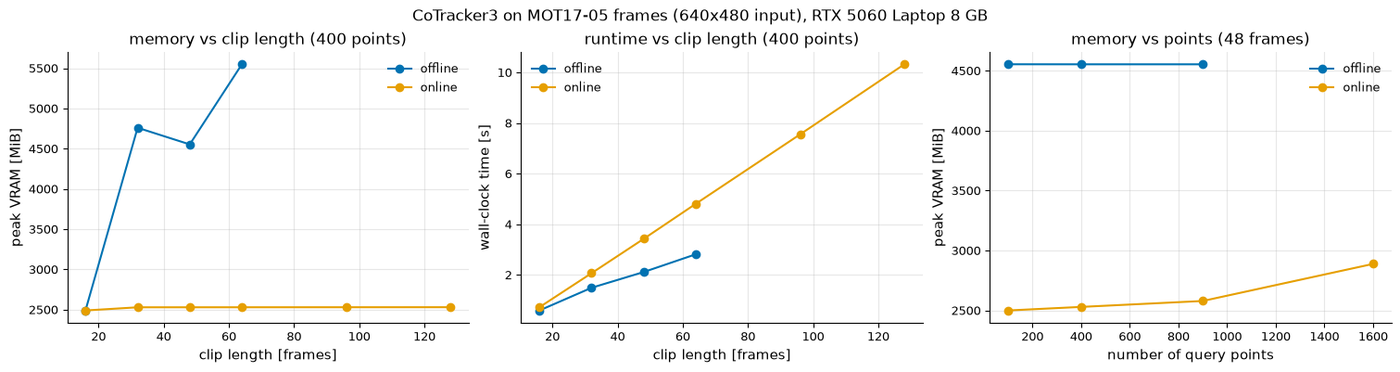

In [14]:
# --- Figure: runtime and peak VRAM vs clip length / number of points, offline vs online ---
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for mode in ["offline", "online"]:
    s = sweep[(sweep["mode"] == mode) & (sweep.points == 400)]
    axes[0].plot(s.frames, s["peak VRAM [MiB]"], marker="o", label=mode)
    axes[1].plot(s.frames, s.seconds, marker="o", label=mode)
    g = sweep[(sweep["mode"] == mode) & (sweep.frames == GRID_T)]
    axes[2].plot(g.points, g["peak VRAM [MiB]"], marker="o", label=mode)
axes[0].set_xlabel("clip length [frames]")
axes[0].set_ylabel("peak VRAM [MiB]")
axes[0].set_title("memory vs clip length (400 points)")
axes[1].set_xlabel("clip length [frames]")
axes[1].set_ylabel("wall-clock time [s]")
axes[1].set_title("runtime vs clip length (400 points)")
axes[2].set_xlabel("number of query points")
axes[2].set_ylabel("peak VRAM [MiB]")
axes[2].set_title(f"memory vs points ({GRID_T} frames)")
for ax in axes:
    ax.legend()
fig.suptitle("CoTracker3 on MOT17-05 frames (640x480 input), RTX 5060 Laptop 8 GB")
cvlab.viz.savefig(fig, PROJECT, "cotracker_scaling")
plt.show()

**Summary tables.** The raw sweep (one row per run; out-of-memory runs are kept and marked)
and the quality numbers measured above.

In [15]:
# --- Summary tables: the sweep, and the quality checks of this notebook ---
display(sweep.round(2))
quality = pd.DataFrame([
    {"experiment": "apple grid 20x20, forward-backward", "metric": "median cycle error [px]",
     "value": fb_stats["median [px]"]},
    {"experiment": "apple grid 20x20, forward-backward", "metric": "share < 2 px", "value": fb_stats["< 2 px"]},
    {"experiment": "MOT17-05 ego-motion", "metric": "precision of 'moving' points on GT persons",
     "value": ego["precision (moving -> on a person)"]},
    {"experiment": "MOT17-05 ego-motion", "metric": "recall of person points", "value": ego["recall (person points flagged)"]},
    {"experiment": "MOT17-05 ego-motion", "metric": "base rate (points on persons)", "value": ego["base rate (points on persons)"]},
    {"experiment": "MOT17-05 online vs offline", "metric": "median distance [px]", "value": agree["median distance [px]"]},
    {"experiment": "MOT17-05 online vs offline", "metric": "visibility agreement", "value": agree["visibility agreement"]},
])
display(quality.round(3))

,mode,frames,points,seconds,FPS,peak VRAM [MiB],note
0,offline,16,400,0.59,26.92,2490.10,NaN
1,offline,32,400,1.49,21.46,4760.35,NaN
2,offline,48,100,1.01,47.34,4553.96,NaN
3,offline,48,400,2.11,22.71,4553.63,NaN
4,offline,48,900,3.90,12.32,4553.65,NaN
5,offline,48,1600,NaN,NaN,NaN,out of memory
6,offline,64,400,2.81,22.74,5549.22,NaN
7,offline,96,400,NaN,NaN,NaN,out of memory
8,offline,128,400,NaN,NaN,NaN,out of memory
9,online,16,400,0.72,22.17,2490.19,NaN


,experiment,metric,value
0,"apple grid 20x20, forward-backward",median cycle error [px],5.495
1,"apple grid 20x20, forward-backward",share < 2 px,0.133
2,MOT17-05 ego-motion,precision of 'moving' points on GT persons,0.267
3,MOT17-05 ego-motion,recall of person points,0.925
4,MOT17-05 ego-motion,base rate (points on persons),0.133
5,MOT17-05 online vs offline,median distance [px],0.881
6,MOT17-05 online vs offline,visibility agreement,0.962


### Takeaways

* **Dense, occlusion-aware point tracks out of the box.** CoTracker3 (25.4 M parameters)
  tracked a 20 x 20 grid through the 50-frame apple clip in 2.40 s; half of the points stay
  visible throughout, and 13.8 % disappear behind an occluder and are picked up again, which
  frame-to-frame optical flow cannot do.
* **Not sub-pixel.** The forward-backward cycle error has a median of 5.5 px on the
  1296 x 720 clip; only 13.3 % of points return within 2 px. The model works at 384 x 512, so
  one model pixel is about 2.5 image pixels horizontally: treat tracks as a few-pixel-accurate
  signal, and use the cycle error to discard the worst ones before feeding geometry.
* **Ego-motion vs moving objects: high recall, low precision.** A per-frame RANSAC homography
  flags 92.5 % of the points on pedestrians as independently moving, but only 26.7 % of the
  flagged points are on a pedestrian (base rate 13.3 %, so 2x better than chance). The
  hand-held camera translates through a 3D street, so the ground close to the camera and the
  far facades cannot share one homography: parallax looks like motion. A real system needs a
  3D model (essential matrix / depth, projects 09 and 12) or a semantic prior on top.
* **Offline vs online is a memory decision.** Offline peak VRAM grows with the clip length
  (2 490 MiB at 16 frames, 5 549 MiB at 64 frames) and ran out of memory at 96 and 128 frames,
  and with 1 600 points at 48 frames. The online model stayed at about 2.5 GB up to 128 frames
  (2 888 MiB for 1 600 points) at 12.4-22.2 FPS for 400 points, and agrees with the offline
  model to a median of 0.88 px with 96.2 % identical visibility flags. For a robot's
  streaming camera, online mode is the practical choice; offline mode is faster on short clips
  (22.7 vs 13.3 FPS at 64 frames).

## Exercises

Solutions: `projects/06_tracking/solutions/`.

**Exercise 1: track a person through an occlusion.** Pick a MOT17-05 pedestrian that is
occluded for a few frames (use the GT `visibility` column, 9th column of `gt.txt`), place 5
query points on their torso in the first frame where they are visible, and plot the predicted
visibility of those points against the GT visibility ratio over time.

In [16]:
# --- Exercise 1: query points on one pedestrian and their visibility through an occlusion ---
# TODO: build queries as rows (t, x, y), run pt.track_offline(offline, clip, queries=queries)
# and plot res["visible"].mean(axis=1) next to the GT visibility of that pedestrian.

**Exercise 2: online vs offline quality.** Compute the forward-backward cycle error of the
**online** model on the apple clip (hint: `pt.track_online` accepts `queries`) and compare its
distribution with the offline model's.

In [17]:
# --- Exercise 2: forward-backward error of the online model ---
# TODO: forward with pt.track_online(online, apple, grid_size=20); backward on apple[::-1]
# with queries (0, x_last, y_last); compare np.median of both error distributions.

**Exercise 3: point tracks vs BoT-SORT's GMC.** Ultralytics' `GMC(method="sparseOptFlow")`
(`ultralytics.trackers.utils.gmc`) estimates a frame-to-frame affine warp. Chain its warps over
the MOT17-05 clip and compare the predicted image-centre displacement with the one from the
CoTracker homographies $H_t$ above. Where do they diverge, and why?

In [18]:
# --- Exercise 3: compare GMC's chained affine warps with the CoTracker homographies ---
# TODO: gmc = GMC(method="sparseOptFlow"); warp_t = gmc.apply(bgr_frame) for each frame;
# chain the 2x3 warps (as 3x3 matrices) and plot the centre displacement next to `pan`.